# <h1><b><center>Smart Interview Performance Analysis</center></b></h1>

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
import warnings
warnings.filterwarnings('ignore')


# <h2><b>Load Dataset</b></h2>

In [15]:
df = pd.read_csv("Smart_Interview_Performance_Dataset.csv")

# <h2><b>Basic Dataset Checking</b></h2>

In [16]:
df.columns

Index(['Age', 'Gender', 'EducationLevel', 'ExperienceYears',
       'PreviousCompanies', 'DistanceFromCompany', 'SkillScore',
       'InterviewScore', 'PersonalityScore', 'HiringDecision'],
      dtype='object')

In [17]:
df.shape

(10000, 10)

In [18]:
df.head()

,Age,Gender,EducationLevel,ExperienceYears,PreviousCompanies,DistanceFromCompany,SkillScore,InterviewScore,PersonalityScore,HiringDecision
0,27,0,3,12,3,2.63,59.09,28.98,72,0
1,40,1,1,14,1,34.78,61.42,33.04,63,0
2,35,1,2,12,4,28.16,62.53,33.87,61,0
3,31,0,2,10,2,47.05,52.94,14.99,87,0
4,28,1,4,10,4,45.49,62.54,46.94,76,0


In [19]:
df = df.drop("DistanceFromCompany", axis=1)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                10000 non-null  int64  
 1   Gender             10000 non-null  int64  
 2   EducationLevel     10000 non-null  int64  
 3   ExperienceYears    10000 non-null  int64  
 4   PreviousCompanies  10000 non-null  int64  
 5   SkillScore         10000 non-null  float64
 6   InterviewScore     10000 non-null  float64
 7   PersonalityScore   10000 non-null  int64  
 8   HiringDecision     10000 non-null  int64  
dtypes: float64(2), int64(7)
memory usage: 703.3 KB


In [21]:
df.isnull().sum()

Age                  0
Gender               0
EducationLevel       0
ExperienceYears      0
PreviousCompanies    0
SkillScore           0
InterviewScore       0
PersonalityScore     0
HiringDecision       0
dtype: int64

In [22]:
df['HiringDecision'].unique()

array([0, 1])

In [23]:
df.duplicated().sum()

np.int64(0)

In [24]:
df.shape

(10000, 9)

In [25]:
df.describe()

,Age,Gender,EducationLevel,ExperienceYears,PreviousCompanies,SkillScore,InterviewScore,PersonalityScore,HiringDecision
count,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,32.609800,0.500900,2.497200,7.00920,2.524000,40.542125,24.685297,72.492500,0.013200
std,6.951257,0.500024,1.115041,4.33668,1.699209,18.961805,14.573583,17.238517,0.114136
min,21.000000,0.000000,1.000000,0.00000,0.000000,0.000000,0.000000,40.000000,0.000000
25%,27.000000,0.000000,2.000000,3.00000,1.000000,25.487500,13.757500,58.000000,0.000000
50%,33.000000,1.000000,2.000000,7.00000,3.000000,40.480000,24.350000,73.000000,0.000000
75%,39.000000,1.000000,3.000000,11.00000,4.000000,55.830000,34.900000,87.000000,0.000000
max,44.000000,1.000000,4.000000,14.00000,5.000000,91.080000,79.390000,100.000000,1.000000


<Axes: >

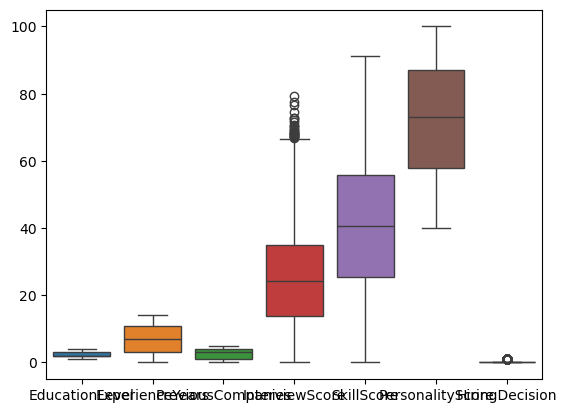

In [26]:
import seaborn as sns
sns.boxplot(data=df[["EducationLevel","ExperienceYears","PreviousCompanies",
                     "InterviewScore","SkillScore", "PersonalityScore","HiringDecision"]])

<Axes: >

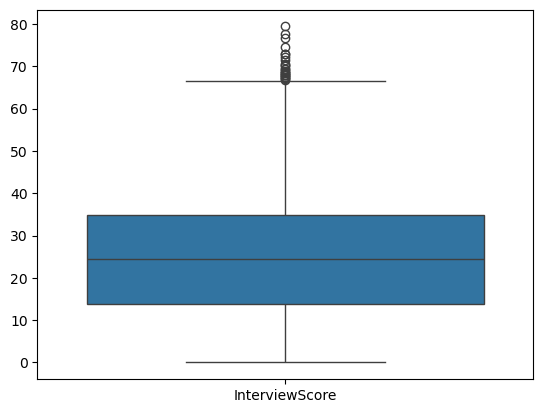

In [27]:
sns.boxplot(data=df[["InterviewScore"]])

In [28]:
df.describe()

,Age,Gender,EducationLevel,ExperienceYears,PreviousCompanies,SkillScore,InterviewScore,PersonalityScore,HiringDecision
count,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,32.609800,0.500900,2.497200,7.00920,2.524000,40.542125,24.685297,72.492500,0.013200
std,6.951257,0.500024,1.115041,4.33668,1.699209,18.961805,14.573583,17.238517,0.114136
min,21.000000,0.000000,1.000000,0.00000,0.000000,0.000000,0.000000,40.000000,0.000000
25%,27.000000,0.000000,2.000000,3.00000,1.000000,25.487500,13.757500,58.000000,0.000000
50%,33.000000,1.000000,2.000000,7.00000,3.000000,40.480000,24.350000,73.000000,0.000000
75%,39.000000,1.000000,3.000000,11.00000,4.000000,55.830000,34.900000,87.000000,0.000000
max,44.000000,1.000000,4.000000,14.00000,5.000000,91.080000,79.390000,100.000000,1.000000


In [29]:
IQR = 34.90 - 13.75

In [30]:
lf = 13.75 - 1.5 * IQR
lf

-17.974999999999998

In [31]:
uf = 34.90 + 1.5 * IQR
uf

66.625

In [32]:
df = df[(df["InterviewScore"] > lf) & (df["InterviewScore"] < uf)]

<Axes: >

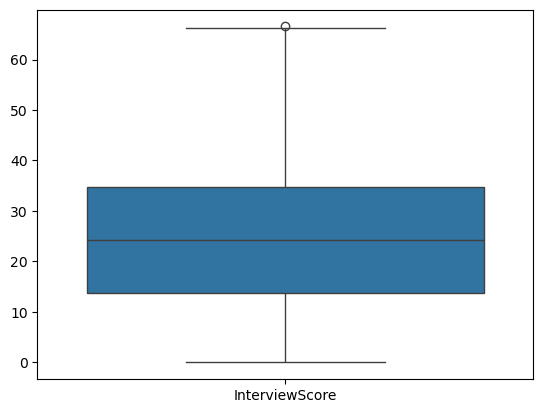

In [33]:
sns.boxplot(data=df[["InterviewScore"]])

# <h2><b>Split Features and Target</b></h2>

In [34]:
X = df.drop("HiringDecision", axis=1)
y = df["HiringDecision"]
#x is input and y is output 
print(X.shape)
print(y.shape)

(9975, 8)
(9975,)


# <h2><b>Train-Test Split</b></h2>

In [35]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
#80% data used in training and 20% data used in testing

# <h2><b>Data Balancing using SMOTE</b></h2>

In [36]:
from imblearn.over_sampling import SMOTE

In [37]:
print("Class distribution BEFORE SMOTE (Train):")
print(y_train.value_counts())

Class distribution BEFORE SMOTE (Train):
HiringDecision
0    7891
1      89
Name: count, dtype: int64


In [38]:
smote =  SMOTE(random_state=42, k_neighbors=5)
#it creates a 5 records for balancing in used k_neighbors

In [39]:
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

In [40]:
print("\nClass distribution AFTER SMOTE (Train):")
print(pd.Series(y_train_res).value_counts())


Class distribution AFTER SMOTE (Train):
HiringDecision
0    7891
1    7891
Name: count, dtype: int64


In [41]:
from sklearn.preprocessing import StandardScaler

In [42]:
scaler = StandardScaler()

In [43]:
X_train_scaled = scaler.fit_transform(X_train_res)  
X_test_scaled  = scaler.transform(X_test)

In [44]:
print("Scaling complete.")
print("Train (scaled) shape:", X_train_scaled.shape)
print("Test  (scaled) shape:", X_test_scaled.shape)

Scaling complete.
Train (scaled) shape: (15782, 8)
Test  (scaled) shape: (1995, 8)


# <h2><b>Train Random Forest Model</b></h2>

In [45]:
from sklearn.ensemble import RandomForestClassifier
#it create a decisions tree consider majority vote and predict value 

In [46]:
model_rf = RandomForestClassifier()

In [47]:
model_rf.fit(X_train_res, y_train_res)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [48]:
y_pred = model_rf.predict(X_test)
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(1995,))

In [49]:
model_rf.score(X_train,y_train),model_rf.score(X_test,y_test)

(1.0, 0.9974937343358395)

# <h2><b>Train XGBoost Model</b></h2> 

In [50]:
from xgboost import XGBClassifier

In [51]:
model_xg = XGBClassifier(n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42)

In [52]:
model_xg.fit(X_train_res, y_train_res)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'mlogloss'


In [53]:
y_pred = model_xg.predict(X_test)
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(1995,))

In [54]:
from sklearn.metrics import classification_report, accuracy_score

In [55]:
model_xg.score(X_train,y_train),model_xg.score(X_test,y_test)

(1.0, 0.9969924812030075)

In [56]:
from sklearn.metrics import confusion_matrix

In [57]:
cm = confusion_matrix(y_test,y_pred)

In [58]:
cm

array([[1966,    4],
       [   2,   23]])

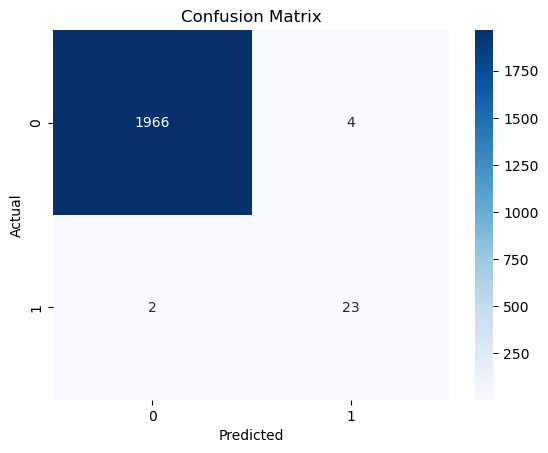

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [60]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1970
           1       0.85      0.92      0.88        25

    accuracy                           1.00      1995
   macro avg       0.93      0.96      0.94      1995
weighted avg       1.00      1.00      1.00      1995



In [61]:
import pickle 
with open("model_rf.pkl","wb") as f:
     pickle.dump(model_rf,f)